# Configurable Project Runs & Study Workspace Management

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)

Reproducible scientific analysis requires separating source code, input trajectories, parameter specifications, and generated artifacts.

MolScope organizes investigations into structured **Study Workspaces**:
```text
my-study/
├── project.json              <-- Validated declarative project specification
├── inputs/                   <-- PDB structures, topologies, and trajectories
├── preparation/              <-- Protonation, imaging, and parameter logs
├── simulations/              <-- OpenMM execution segments & checkpoints
└── runs/
    └── run-001/              <-- Fully auditable, stage-grouped run artifacts
        ├── resolved_project.json
        ├── provenance.json
        ├── features/
        ├── discovery/
        ├── predictive/
        └── report/
            ├── extraction_report.html
            ├── trajectory_1_contacts.png
            └── trajectory_1_geometry.png
```


## 1. Initializing a Study Workspace via Python API

A Study Workspace establishes an isolated filesystem hierarchy ensuring raw input data remain immutable, generated simulations are recorded under designated directories, and each analysis run captures resolved configurations and cryptographic provenance.


In [1]:
import shutil
from pathlib import Path
from molscope.core.workspace import initialize_study, begin_run

# Standard output location in results directory
workspace_dir = Path("results/workspace_demo")
if not workspace_dir.parent.is_dir() and Path("../results").is_dir():
    workspace_dir = Path("../results/workspace_demo")

study_destination = workspace_dir / "villin_study"
if study_destination.exists():
    shutil.rmtree(study_destination)

# Initialize a managed study workspace
study_path = initialize_study(destination=study_destination, project_id="villin_study")
print(f"Study workspace initialized at: {study_path}")

# Check directory structure
print("\nStudy workspace contents:")
for child in sorted(study_path.iterdir()):
    kind = "directory" if child.is_dir() else "file"
    print(f"  - {child.name:20s} ({kind})")


Study workspace initialized at: /Users/nirav/Docs/molscope/results/workspace_demo/villin_study

Study workspace contents:
  - README.md            (file)
  - cache                (directory)
  - inputs               (directory)
  - preparation          (directory)
  - project.json         (file)
  - runs                 (directory)
  - simulations          (directory)


## 2. Declarative `project.json` Specification

A MolScope study is governed by a validated `project.json` declaration.
It declares:
- **Systems & Ensembles**: Topology, replica trajectories, and biological metadata
- **Supervised Labels**: Explicit trajectory-level targets with declared provenance (preventing temporal data leakage)
- **Analysis Policy**: Selected feature extraction plugins, generic sampling parameters, and plugin-specific options


In [2]:
import json
from dataclasses import asdict
from molscope.core.project import (
    ProjectSpec, SystemSpec, EnsembleSpec, ReplicaSpec, LabelSpec, AnalysisSpec, load_project_spec
)

# Locate structure fixture with fallback to 1A22
candidate_paths = [
    Path("data/2RJY/topology.pdb"),
    Path("../data/2RJY/topology.pdb"),
    Path("tests/fixtures/1A22.pdb"),
    Path("../tests/fixtures/1A22.pdb"),
]
pdb_path = next((p.resolve() for p in candidate_paths if p.is_file()), None)
if pdb_path is None:
    raise FileNotFoundError("Could not locate a structure fixture (checked data/2RJY and tests/fixtures/1A22.pdb).")

print(f"Using structure fixture: {pdb_path}")

# Construct declarative specification
project = ProjectSpec(
    project_id="workspace_example",
    systems=(
        SystemSpec(
            system_id="hgh_receptor",
            topology=pdb_path,
            ensembles=(
                EnsembleSpec(
                    ensemble_id="wild_type_ensemble",
                    replicas=(
                        ReplicaSpec(
                            replica_id="rep_01",
                            trajectory=pdb_path,
                            metadata={"condition": "apo", "temperature_k": 300},
                        ),
                    ),
                ),
            ),
        ),
    ),
    labels=(
        LabelSpec(
            label_id="condition_label",
            label_type="categorical",
            level="trajectory",
            source="external_annotation",
            assignments={"hgh_receptor:wild_type_ensemble:rep_01": "apo"},
            description="Experimental binding state annotation",
        ),
    ),
    analysis=AnalysisSpec(
        generic_feature_parameters={"frame_stride": 1, "max_frames": 50},
        plugins=("protein.ca_distances_contacts",),
        plugin_parameters={"protein.ca_distances_contacts": {"selection": "resid 1-35"}},
    ),
)

# Verify asdict(project) serialization:
# Dataclass serialization retains Path instances; default=str safely serializes PosixPath objects
spec_path = study_path / "project.json"
project_dict = asdict(project)
spec_path.write_text(json.dumps(project_dict, indent=2, default=str), encoding="utf-8")
print(f"Written validated project specification to: {spec_path}")

# Validate round-trip loading
loaded_project = load_project_spec(spec_path)
print(f"Loaded project ID: {loaded_project.project_id}")
print(f"Trajectory count:  {len(loaded_project.trajectory_inputs())}")
print(f"Missing paths:     {loaded_project.validate_paths()}")


Using structure fixture: /Users/nirav/Docs/molscope/tests/fixtures/1A22.pdb
Written validated project specification to: /Users/nirav/Docs/molscope/results/workspace_demo/villin_study/project.json
Loaded project ID: workspace_example
Trajectory count:  1
Missing paths:     []


## 3. Starting a Managed Study Run with Full Provenance

The `begin_run` lifecycle primitive prepares an auditable run directory inside `runs/<run_id>`, records the resolved `project.json`, computes cryptographic SHA-256 fingerprints of all declared inputs, and creates the initial `provenance.json`.


In [3]:
# Begin an auditable run within the study
audit_run_dir, audit_provenance = begin_run(study=study_path, run_id="audit_run_01")

print(f"Run directory created: {audit_run_dir}")
print(f"Run provenance keys:   {list(audit_provenance.keys())}")
print(f"Status:                {audit_provenance.get('status')}")
print(f"Created at:            {audit_provenance.get('created_at_utc') or audit_provenance.get('started_at')}")
print(f"Python interpreter:    {audit_provenance.get('python')}")
print(f"Recorded input fingerprints ({len(audit_provenance.get('inputs', []))} file(s)):")
for inp in audit_provenance.get("inputs", []):
    print(f"  - {inp['path']}\n    SHA-256: {inp['sha256']}")


Run directory created: /Users/nirav/Docs/molscope/results/workspace_demo/villin_study/runs/audit_run_01
Run provenance keys:   ['project_id', 'run_id', 'status', 'started_at', 'created_at_utc', 'python', 'inputs']
Status:                running
Created at:            2026-11-19T12:05:47.077800+00:00
Python interpreter:    3.13.13
Recorded input fingerprints (1 file(s)):
  - /Users/nirav/Docs/molscope/tests/fixtures/1A22.pdb
    SHA-256: 2badf46c7244ca4edb10d4517701b02544a56ebd8bbc9c8e32593135f0c3d389


## 4. Executing the Managed Project Workflow

MolScope study runs can be dispatched from the command line:
```bash
python -m molscope run --study results/workspace_demo/villin_study --run-id production_run_01 --extract-only
```
Or directly executed using MolScope's programmatic API via `study_run`:


In [4]:
from molscope.cli.main import study_run

# Execute full workflow with extraction and artifact organization
run_id = "production_run_01"
study_run(["--study", str(study_path), "--run-id", run_id, "--extract-only"])

prod_run_dir = study_path / "runs" / run_id
print(f"\nCompleted study run at: {prod_run_dir}")


Completed run: /Users/nirav/Docs/molscope/results/workspace_demo/villin_study/runs/production_run_01

Completed study run at: /Users/nirav/Docs/molscope/results/workspace_demo/villin_study/runs/production_run_01


## 5. Artifact Inspection & Embedded Visualizations

A completed MolScope study run automatically organizes native artifacts into structured stage directories:
- `features/`: Tabular representations (`frame_features.parquet`, `feature_summary.csv`, `frame_manifest.csv`)
- `validation/`: Extraction integrity records and label definitions (`extraction_evidence.json`, `label_definitions.json`)
- `report/`: Generated extraction HTML summary and inline diagnostic figures (`trajectory_1_contacts.png`, `trajectory_1_geometry.png`)
- `logs/`: Isolated execution log (`run.log`)
- Root: Immutable run metadata (`resolved_project.json`, `provenance.json`, `artifacts.json`)


In [5]:
import pandas as pd
from IPython.display import Image, display

# 1. Inspect generated directory tree
print("Artifact hierarchy in run directory:")
for root_path in sorted(prod_run_dir.iterdir()):
    if root_path.is_dir():
        print(f"  📁 {root_path.name}/")
        for sub in sorted(root_path.iterdir()):
            print(f"      📄 {sub.name}")
    else:
        print(f"  📄 {root_path.name}")

# 2. Inspect extracted feature metrics
summary_csv = prod_run_dir / "features" / "feature_summary.csv"
if summary_csv.is_file():
    df_summary = pd.read_csv(summary_csv, index_col=0)
    print(f"\nTotal extracted features: {len(df_summary)}")
    print("\nSample feature distribution statistics:")
    display(df_summary.head(8))


Artifact hierarchy in run directory:
  📁 .native/
      📄 extraction_evidence.json
      📄 extraction_report.html
      📄 feature_summary.csv
      📄 frame_features.csv
      📄 frame_features.parquet
      📄 frame_manifest.csv
      📄 frame_manifest.parquet
      📄 label_definitions.json
      📄 session_config.json
      📄 session_storage.json
      📄 trajectory_1_contact_occupancy.csv
      📄 trajectory_1_contacts.png
      📄 trajectory_1_geometry.png
  📄 artifacts.json
  📁 features/
      📄 feature_summary.csv
      📄 frame_features.csv
      📄 frame_features.parquet
      📄 frame_manifest.csv
      📄 frame_manifest.parquet
      📄 session_config.json
      📄 session_storage.json
      📄 trajectory_1_contact_occupancy.csv
  📁 logs/
      📄 run.log
  📄 provenance.json
  📁 report/
      📄 extraction_evidence.json
      📄 extraction_report.html
      📄 feature_summary.csv
      📄 frame_features.csv
      📄 frame_features.parquet
      📄 frame_manifest.csv
      📄 frame_manifest.parquet


,count,mean,std,min,25%,50%,75%,max
GEOM_global_radius_gyration,1.0,2.286717e+01,NaN,2.286717e+01,2.286717e+01,2.286717e+01,2.286717e+01,2.286717e+01
GEOM_global_asphericity,1.0,2.552178e-01,NaN,2.552178e-01,2.552178e-01,2.552178e-01,2.552178e-01,2.552178e-01
DYN_kabsch_rmsd_to_first_frame,1.0,3.149538e-07,NaN,3.149538e-07,3.149538e-07,3.149538e-07,3.149538e-07,3.149538e-07
GEOM_component_com_distance__chain_A_protein__chain_B_protein,1.0,2.427487e+01,NaN,2.427487e+01,2.427487e+01,2.427487e+01,2.427487e+01,2.427487e+01
GEOM_component_min_atom_distance__chain_A_protein__chain_B_protein,1.0,2.645880e+00,NaN,2.645880e+00,2.645880e+00,2.645880e+00,2.645880e+00,2.645880e+00
CONTACT_pair_count__chain_A_protein__chain_B_protein,1.0,4.240000e+02,NaN,4.240000e+02,4.240000e+02,4.240000e+02,4.240000e+02,4.240000e+02
CONTACT_pair_fraction__chain_A_protein__chain_B_protein,1.0,1.832841e-04,NaN,1.832841e-04,1.832841e-04,1.832841e-04,1.832841e-04,1.832841e-04
CA_DISTANCE_angstrom__A__PHE_1__A__ILE_4,1.0,1.012596e+01,NaN,1.012596e+01,1.012596e+01,1.012596e+01,1.012596e+01,1.012596e+01


### Embedded Extraction Figures & Diagnostic Visualizations

Below are the diagnostic figures automatically generated and organized by MolScope during the feature extraction stage:


Embedding diagnostic contact map: trajectory_1_contacts.png


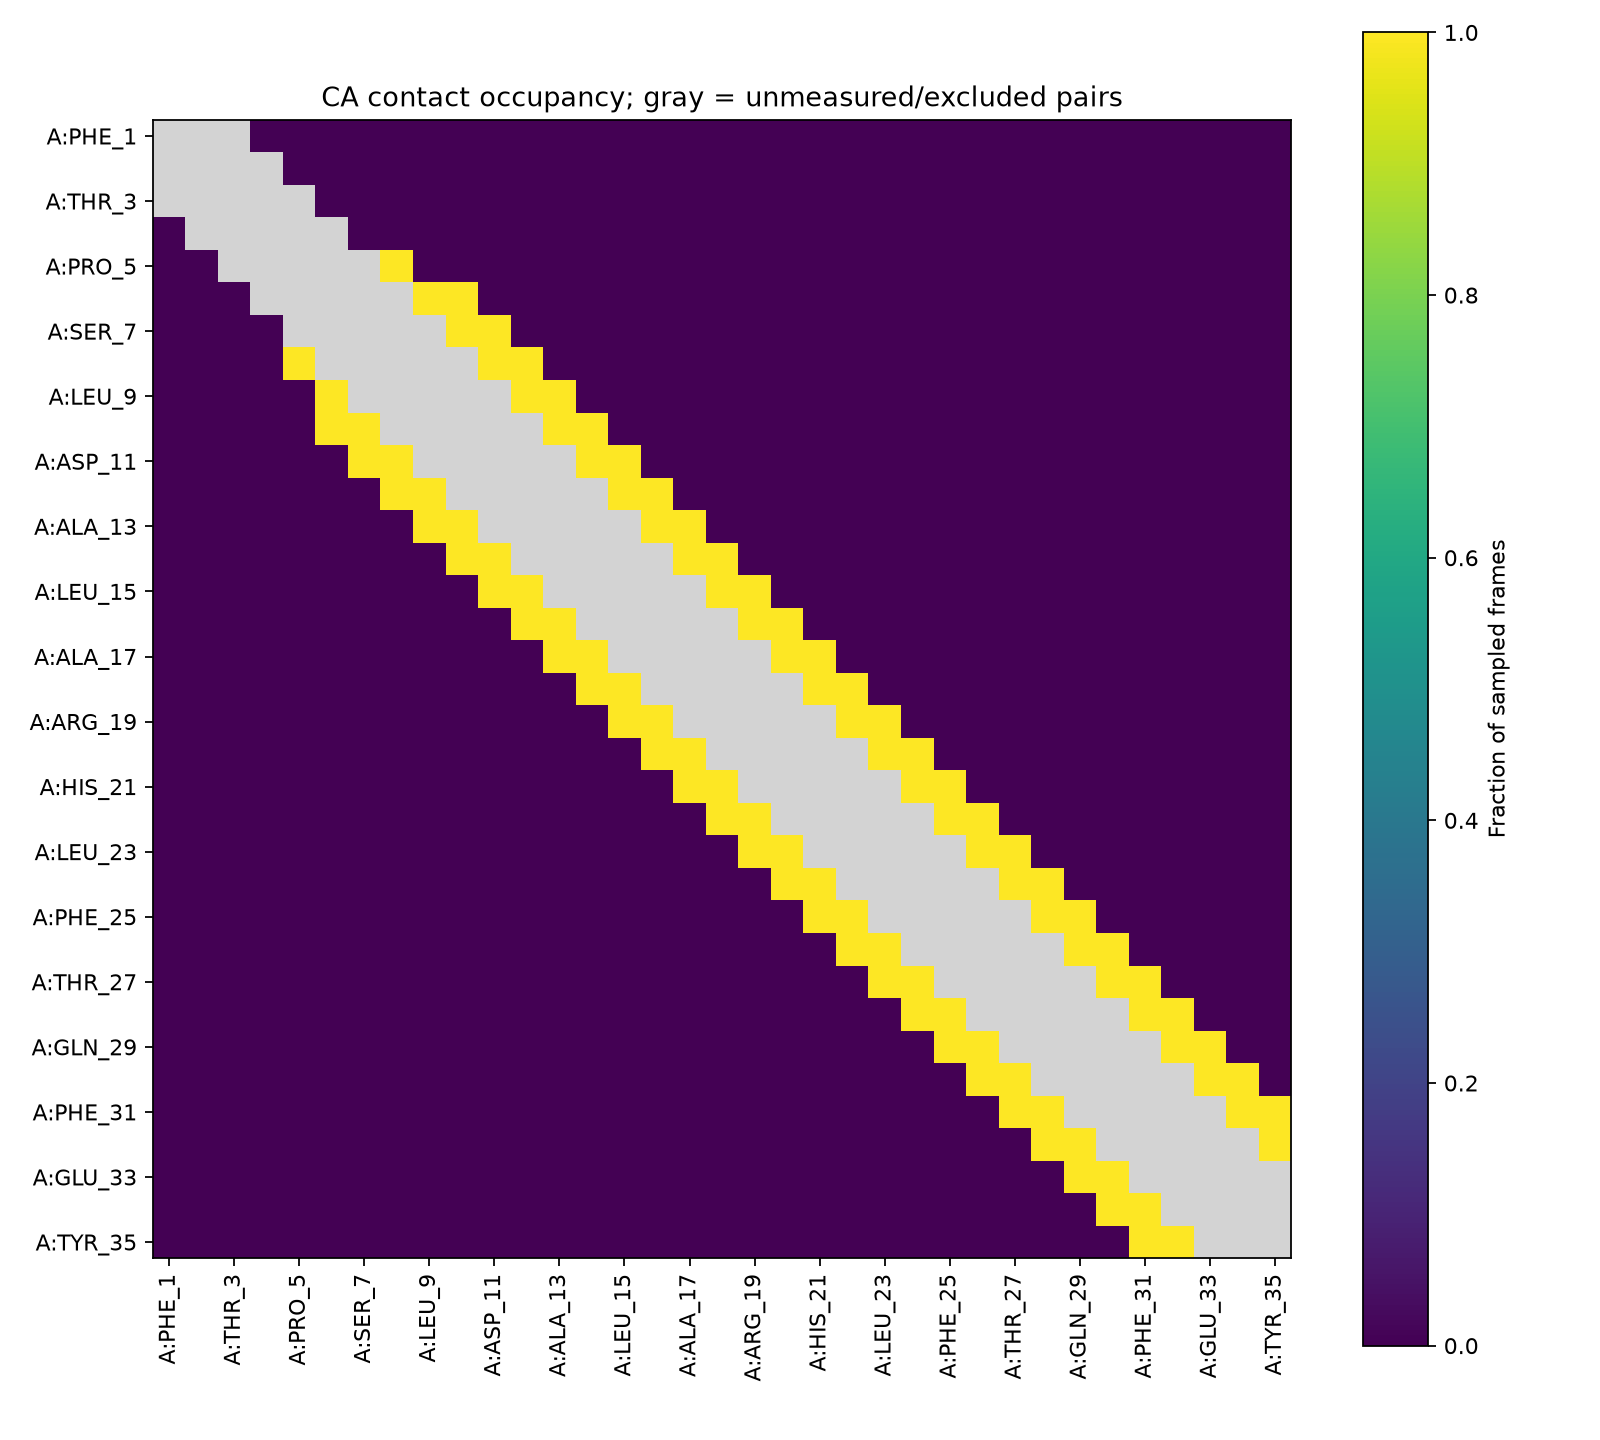

Embedding diagnostic geometry plot: trajectory_1_geometry.png


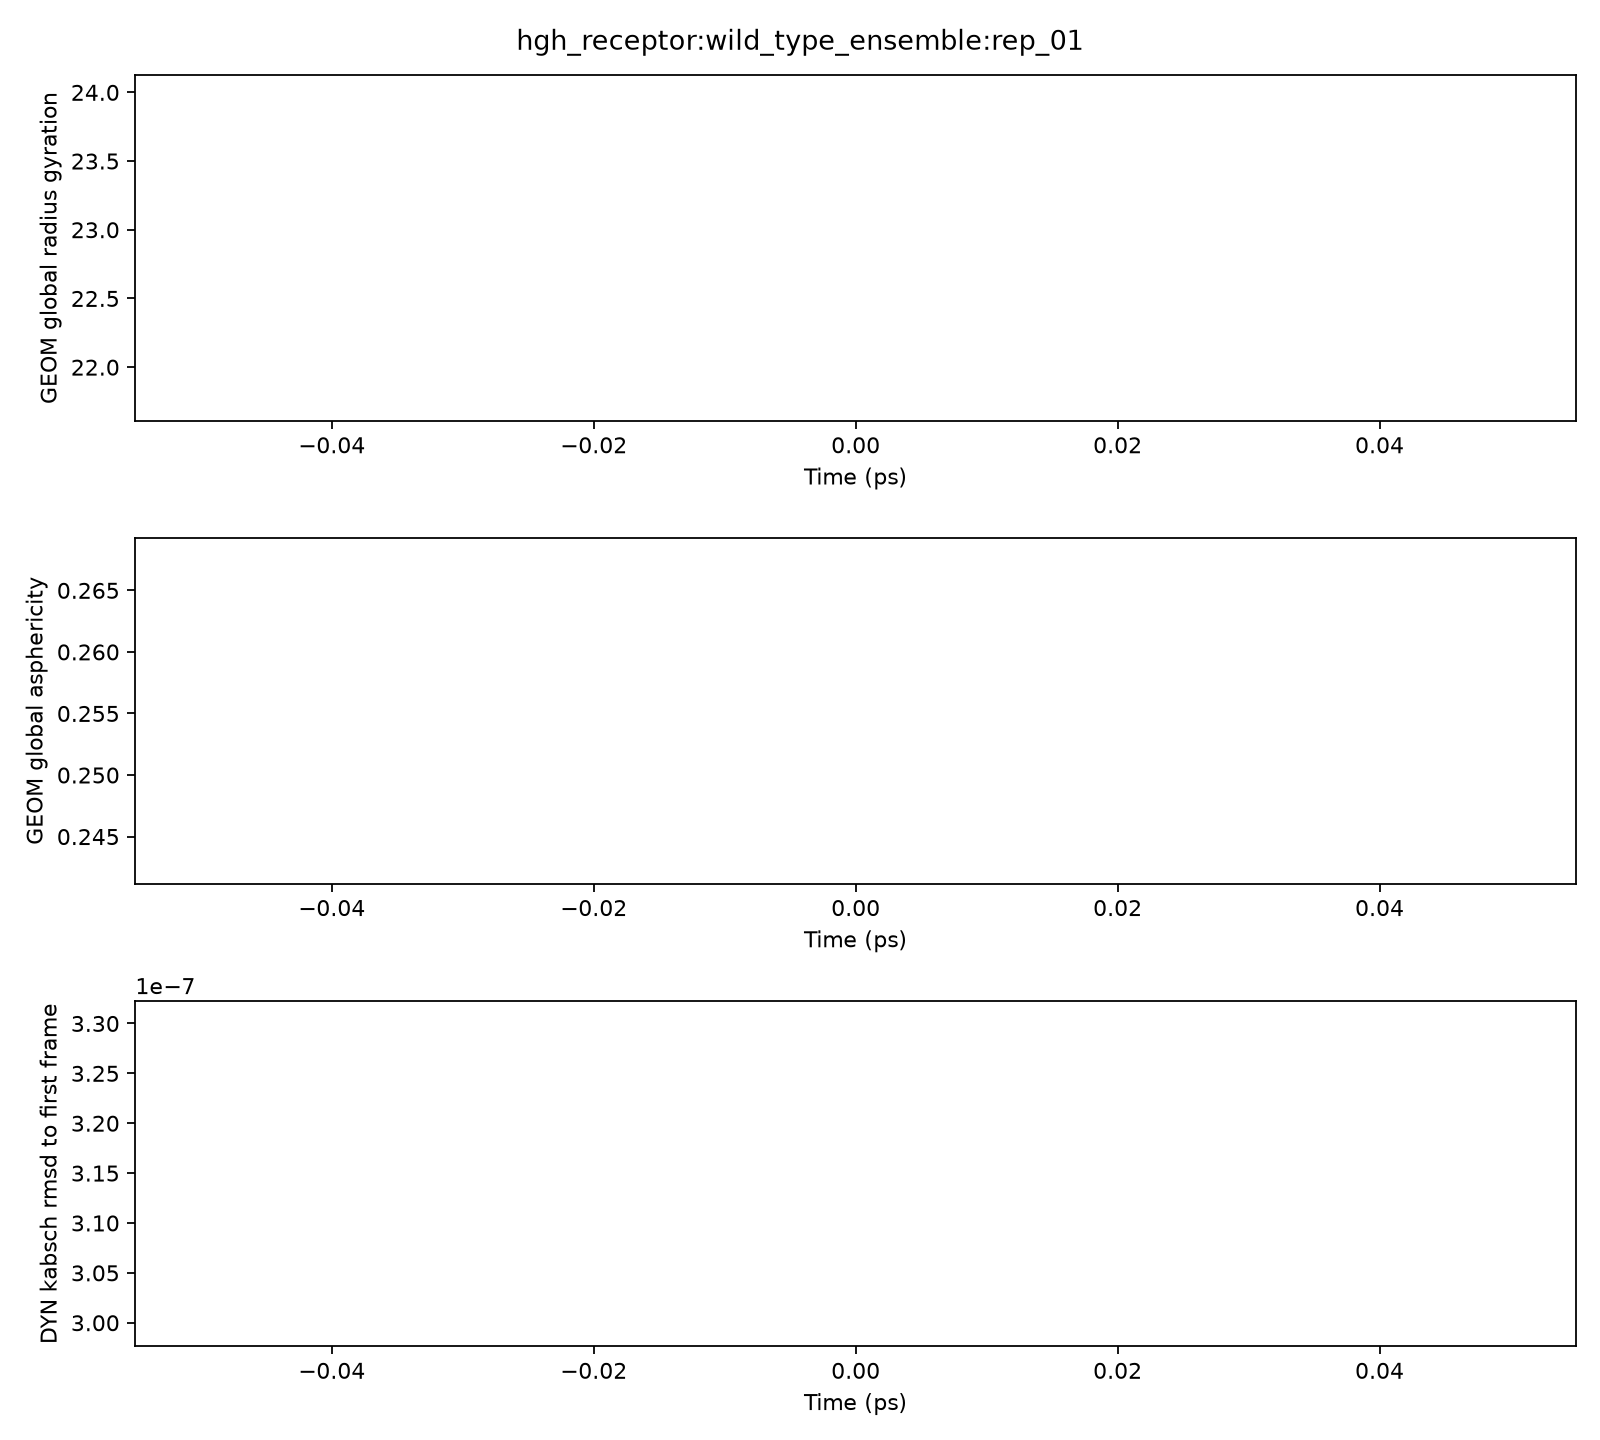

In [6]:
# Embed and display the contact map generated during extraction
contacts_png = prod_run_dir / "report" / "trajectory_1_contacts.png"
if contacts_png.is_file():
    print(f"Embedding diagnostic contact map: {contacts_png.name}")
    display(Image(filename=str(contacts_png), width=650))

# Embed and display the geometry distribution plot
geometry_png = prod_run_dir / "report" / "trajectory_1_geometry.png"
if geometry_png.is_file():
    print(f"Embedding diagnostic geometry plot: {geometry_png.name}")
    display(Image(filename=str(geometry_png), width=650))


### Summary of Geometric and Biophysical Features

We can also inspect the global macromolecular shape descriptors directly extracted from the trajectory:


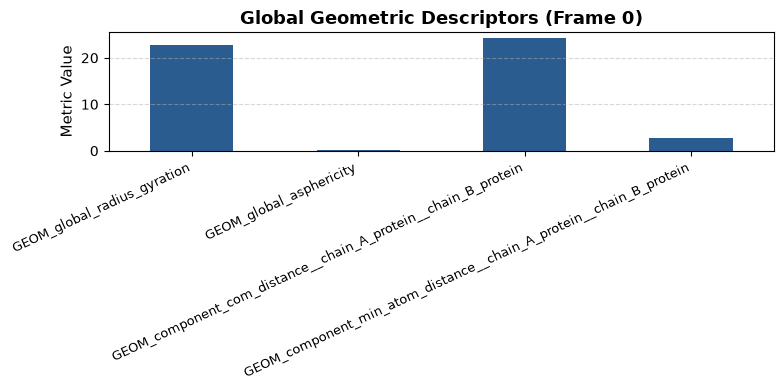


Finalized Run Provenance:
  Status:       completed
  Started:      2026-11-19T12:05:47.082891+00:00
  Finished:     2026-11-19T12:05:48.509541+00:00
  Arguments:    --study /Users/nirav/Docs/molscope/results/workspace_demo/villin_study --run-id production_run_01 --extract-only


In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

# Load frame features to plot geometric properties
features_csv = prod_run_dir / "features" / "frame_features.csv"
if features_csv.is_file():
    df_features = pd.read_csv(features_csv)
    geom_cols = [c for c in df_features.columns if c.startswith("GEOM_")][:5]
    
    if geom_cols:
        fig, ax = plt.subplots(figsize=(8, 4))
        df_features[geom_cols].iloc[0].plot(kind="bar", ax=ax, color="#2b5c8f")
        ax.set_title("Global Geometric Descriptors (Frame 0)", fontsize=13, fontweight="bold")
        ax.set_ylabel("Metric Value", fontsize=11)
        ax.set_xticklabels(geom_cols, rotation=25, ha="right", fontsize=9)
        ax.grid(axis="y", linestyle="--", alpha=0.5)
        plt.tight_layout()
        display(fig)
        plt.close(fig)

# Inspect final run provenance
provenance_json = prod_run_dir / "provenance.json"
if provenance_json.is_file():
    final_prov = json.loads(provenance_json.read_text(encoding="utf-8"))
    print("\nFinalized Run Provenance:")
    print(f"  Status:       {final_prov.get('status')}")
    print(f"  Started:      {final_prov.get('started_at')}")
    print(f"  Finished:     {final_prov.get('finished_at')}")
    print(f"  Arguments:    {' '.join(final_prov.get('arguments', []))}")


## 6. Summary

The MolScope Study Workspace pattern provides:
1. **Clear Directory Separation**: Code, inputs, simulations, and analysis runs are strictly partitioned.
2. **Declarative Contracts**: `project.json` documents all systems, topology/trajectory inputs, categorical labels, and plugin configurations.
3. **Cryptographic Provenance**: SHA-256 digests and environment records are captured automatically at the start of each run.
4. **Structured Artifacts**: Extracted features, validations, reports, and logs are cleanly organized for downstream statistical learning and state discovery.
